#DAP ASSIGNMENT
Improving Marketing Campaign Effectiveness Through Customer Spending and Behaviour Analysis

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_excel("/content/marketing_campaign_Dataset_DAP.xlsx")


In [ ]:
print(df.head)

<bound method NDFrame.head of          ID  Year_Birth   Education Marital_Status   Income Level   Income  \
0      5524        1957  Graduation         Single  Middle Income  58138.0   
1      2174        1954  Graduation         Single  Middle Income  46344.0   
2      4141        1965  Graduation       Together  Middle Income  71613.0   
3      6182        1984  Graduation       Together     Low Income  26646.0   
4      5324        1981         PhD        Married  Middle Income  58293.0   
...     ...         ...         ...            ...            ...      ...   
2235  10870        1967  Graduation        Married  Middle Income  61223.0   
2236   4001        1946         PhD       Together  Middle Income  64014.0   
2237   7270        1981  Graduation       Divorced  Middle Income  56981.0   
2238   8235        1956      Master       Together  Middle Income  69245.0   
2239   9405        1954         PhD        Married  Middle Income  52869.0   

      Kidhome  Teenhome Dt_Custom

In [ ]:
print(df.shape)
df.info()
print(df.dtypes)

(2240, 30)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 30 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   ID                   2240 non-null   int64         
 1   Year_Birth           2240 non-null   int64         
 2   Education            2240 non-null   object        
 3   Marital_Status       2240 non-null   object        
 4   Income Level         2240 non-null   object        
 5   Income               2216 non-null   float64       
 6   Kidhome              2240 non-null   int64         
 7   Teenhome             2240 non-null   int64         
 8   Dt_Customer          2240 non-null   datetime64[ns]
 9   Recency              2240 non-null   int64         
 10  MntWines             2240 non-null   int64         
 11  MntFruits            2240 non-null   int64         
 12  MntMeatProducts      2240 non-null   int64         
 13  MntFishProducts      2

Missing Values

In [ ]:
print(df.isna().sum())

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income Level            0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64


Decision Making Structures Nested IF Statement in Python

In [ ]:
# A simple marketing example using the first customer's spending
customer_spending = df.loc[0, ["MntWines", "MntFruits", "MntMeatProducts",
                               "MntFishProducts", "MntSweetProducts", "MntGoldProds"]].sum()
customer_purchases = df.loc[0, ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]].sum()
print("First customer's product spending:", customer_spending)
print("First customer's number of purchases:", customer_purchases)

if customer_spending > df[["MntWines", "MntFruits", "MntMeatProducts",
                            "MntFishProducts", "MntSweetProducts", "MntGoldProds"]].sum(axis=1).median():
    print("This customer spends above the dataset median.")
else:
    print("This customer spends at or below the dataset median.")

First customer's product spending: 1617
First customer's number of purchases: 22
This customer spends above the dataset median.


Loading data, functions, decisions, loops, lists and dictionaries

In [ ]:
# Create the main measures used throughout the notebook
spending_cols = ["MntWines", "MntFruits", "MntMeatProducts",
                 "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
channel_cols = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
campaign_cols = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5"]

df["Total_Spending"] = df[spending_cols].sum(axis=1)
df["Total_Purchases"] = df[channel_cols].sum(axis=1)
df["Campaign_Acceptance_Count"] = df[campaign_cols].sum(axis=1)
print(df[["ID", "Total_Spending", "Total_Purchases", "Campaign_Acceptance_Count"]].head())

     ID  Total_Spending  Total_Purchases  Campaign_Acceptance_Count
0  5524            1617               22                          0
1  2174              27                4                          0
2  4141             776               20                          0
3  6182              53                6                          0
4  5324             422               14                          0


In [ ]:
# A user-defined function
def spending_band(value):
    if value >= df["Total_Spending"].quantile(0.75):
        return "High spending"
    elif value >= df["Total_Spending"].median():
        return "Medium spending"
    else:
        return "Lower spending"

df["Spending_Segment"] = df["Total_Spending"].apply(spending_band)
display(df[["ID", "Total_Spending", "Spending_Segment"]].head())

,ID,Total_Spending,Spending_Segment
0,5524,1617,High spending
1,2174,27,Lower spending
2,4141,776,Medium spending
3,6182,53,Lower spending
4,5324,422,Medium spending


In [ ]:
# If / elif / else decision using average latest campaign response
response_rate = df["Response"].mean() * 100
if response_rate >= 30:
    print("Latest campaign acceptance is relatively high in this sample.")
elif response_rate >= 15:
    print("Latest campaign acceptance is moderate in this sample.")
else:
    print("Latest campaign acceptance is relatively low in this sample.")
print("Observed response rate:", round(response_rate, 2), "%")

Latest campaign acceptance is relatively low in this sample.
Observed response rate: 14.91 %


In [ ]:
# Nested if: combine campaign response and spending
mean_spend = df["Total_Spending"].mean()
if response_rate >= 15:
    if mean_spend >= df["Total_Spending"].median():
        print("The sample has a moderate-or-higher response rate and average spending at/above median.")
    else:
        print("The response rate meets the threshold, but average spending is below the median.")
else:
    print("The latest campaign response rate is below the selected threshold.")

The latest campaign response rate is below the selected threshold.


In [ ]:
# For loop: classify the first 10 customers by latest campaign response
for response in df["Response"].head(10):
    if response == 1:
        print("Accepted latest campaign")
    else:
        print("Did not accept latest campaign")

Accepted latest campaign
Did not accept latest campaign
Did not accept latest campaign
Did not accept latest campaign
Did not accept latest campaign
Did not accept latest campaign
Did not accept latest campaign
Did not accept latest campaign
Accepted latest campaign
Did not accept latest campaign


In [ ]:
# For loop with range() and iloc
for i in range(min(10, len(df))):
    print(df["ID"].iloc[i], df["Total_Spending"].iloc[i])

5524 1617
2174 27
4141 776
6182 53
5324 422
7446 716
965 590
6177 169
4855 46
5899 49


In [ ]:
# While loop: inspect first five customers' spending
i = 0
while i < min(5, len(df)):
    print("Customer ID:", df["ID"].iloc[i], "| Spending:", df["Total_Spending"].iloc[i])
    i += 1

Customer ID: 5524 | Spending: 1617
Customer ID: 2174 | Spending: 27
Customer ID: 4141 | Spending: 776
Customer ID: 6182 | Spending: 53
Customer ID: 5324 | Spending: 422


In [ ]:
# Lists and dictionaries
main_variables = spending_cols + channel_cols + ["Income", "Response"]
variable_purpose = {
    "Income": "Customer income",
    "Total_Spending": "Sum of spending across six product categories",
    "Total_Purchases": "Sum of web, catalogue and store purchases",
    "Response": "Acceptance of the latest campaign (1=yes, 0=no)"
}
print("Variables selected:", main_variables)
print("Variable dictionary:", variable_purpose)

Variables selected: ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'Income', 'Response']
Variable dictionary: {'Income': 'Customer income', 'Total_Spending': 'Sum of spending across six product categories', 'Total_Purchases': 'Sum of web, catalogue and store purchases', 'Response': 'Acceptance of the latest campaign (1=yes, 0=no)'}


In [ ]:
# NumPy array and operations
spending_array = df["Total_Spending"].dropna().to_numpy()
print("First five values:", spending_array[:5])
print("Average:", np.mean(spending_array))
print("10% increase scenario for first five customers:", spending_array[:5] * 1.10)

First five values: [1617   27  776   53  422]
Average: 605.7982142857143
10% increase scenario for first five customers: [1778.7   29.7  853.6   58.3  464.2]


In [ ]:
# Pandas Series and DataFrame selection
income_series = df["Income"]
print(type(income_series))
print(income_series.head())
selected_data = df[["ID", "Education", "Income", "Total_Spending", "Response"]]
print(type(selected_data))
display(selected_data.head())

# Label-based and position-based selection
display(df.loc[:4, ["ID", "Income", "Total_Spending"]])
display(df.iloc[:5, :5])

<class 'pandas.core.series.Series'>
0    58138.0
1    46344.0
2    71613.0
3    26646.0
4    58293.0
Name: Income, dtype: float64
<class 'pandas.core.frame.DataFrame'>


,ID,Education,Income,Total_Spending,Response
0,5524,Graduation,58138.0,1617,1
1,2174,Graduation,46344.0,27,0
2,4141,Graduation,71613.0,776,0
3,6182,Graduation,26646.0,53,0
4,5324,PhD,58293.0,422,0


,ID,Income,Total_Spending
0,5524,58138.0,1617
1,2174,46344.0,27
2,4141,71613.0,776
3,6182,26646.0,53
4,5324,58293.0,422


,ID,Year_Birth,Education,Marital_Status,Income Level
0,5524,1957,Graduation,Single,Middle Income
1,2174,1954,Graduation,Single,Middle Income
2,4141,1965,Graduation,Together,Middle Income
3,6182,1984,Graduation,Together,Low Income
4,5324,1981,PhD,Married,Middle Income


In [ ]:
# Pandas Series and DataFrame selection
income_series = df["Income"]
print(type(income_series))
print(income_series.head())
selected_data = df[["ID", "Education", "Income", "Total_Spending", "Response"]]
print(type(selected_data))
display(selected_data.head())

# Label-based and position-based selection
display(df.loc[:4, ["ID", "Income", "Total_Spending"]])
display(df.iloc[:5, :5])

<class 'pandas.core.series.Series'>
0    58138.0
1    46344.0
2    71613.0
3    26646.0
4    58293.0
Name: Income, dtype: float64
<class 'pandas.core.frame.DataFrame'>


,ID,Education,Income,Total_Spending,Response
0,5524,Graduation,58138.0,1617,1
1,2174,Graduation,46344.0,27,0
2,4141,Graduation,71613.0,776,0
3,6182,Graduation,26646.0,53,0
4,5324,PhD,58293.0,422,0


,ID,Income,Total_Spending
0,5524,58138.0,1617
1,2174,46344.0,27
2,4141,71613.0,776
3,6182,26646.0,53
4,5324,58293.0,422


,ID,Year_Birth,Education,Marital_Status,Income Level
0,5524,1957,Graduation,Single,Middle Income
1,2174,1954,Graduation,Single,Middle Income
2,4141,1965,Graduation,Together,Middle Income
3,6182,1984,Graduation,Together,Low Income
4,5324,1981,PhD,Married,Middle Income


#Exploratory data analysis (EDA)

In [ ]:
print("Shape (rows, columns):", df.shape)
print("Column names:")
print(df.columns.tolist())
print("Index:")
print(df.index)
print("Data types:")
print(df.dtypes)
print("Dataset information:")
df.info()

Shape (rows, columns): (2240, 34)
Column names:
['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income Level', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response', 'Total_Spending', 'Total_Purchases', 'Campaign_Acceptance_Count', 'Spending_Segment']
Index:
RangeIndex(start=0, stop=2240, step=1)
Data types:
ID                                    int64
Year_Birth                            int64
Education                            object
Marital_Status                       object
Income Level                         object
Income                              float64
Kidhome                               int64
Teenhome                           

In [ ]:
# Variable classification — IDs and binary codes are not continuous measurements
quantitative_cols = ["Year_Birth", "Income", "Kidhome", "Teenhome", "Recency"] + spending_cols + channel_cols + ["NumWebVisitsMonth"]
categorical_cols = ["Education", "Marital_Status", "Income Level", "Spending_Segment"]
binary_cols = campaign_cols + ["Complain", "Response"]
date_cols = ["Dt_Customer"]
id_cols = ["ID"]
print("Quantitative candidates:", len(quantitative_cols), quantitative_cols)
print("Categorical:", len(categorical_cols), categorical_cols)
print("Binary indicators:", len(binary_cols), binary_cols)
print("Date:", date_cols, "| IDs:", id_cols)

Quantitative candidates: 15 ['Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth']
Categorical: 4 ['Education', 'Marital_Status', 'Income Level', 'Spending_Segment']
Binary indicators: 7 ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'Complain', 'Response']
Date: ['Dt_Customer'] | IDs: ['ID']


#DESCRIPTIVE STATISTICS

In [ ]:
# Descriptive statistics for numeric columns
display(df[quantitative_cols].describe().round(2))
print("Categorical summaries:")
display(df[categorical_cols].describe())

,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth
count,2240.00,2216.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00
mean,1968.81,52247.25,0.44,0.51,49.11,303.94,26.30,166.95,37.53,27.06,44.02,4.08,2.66,5.79,5.32
std,11.98,25173.08,0.54,0.54,28.96,336.60,39.77,225.72,54.63,41.28,52.17,2.78,2.92,3.25,2.43
min,1893.00,1730.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,1959.00,35303.00,0.00,0.00,24.00,23.75,1.00,16.00,3.00,1.00,9.00,2.00,0.00,3.00,3.00
50%,1970.00,51381.50,0.00,0.00,49.00,173.50,8.00,67.00,12.00,8.00,24.00,4.00,2.00,5.00,6.00
75%,1977.00,68522.00,1.00,1.00,74.00,504.25,33.00,232.00,50.00,33.00,56.00,6.00,4.00,8.00,7.00
max,1996.00,666666.00,2.00,2.00,99.00,1493.00,199.00,1725.00,259.00,263.00,362.00,27.00,28.00,13.00,20.00


Categorical summaries:


,Education,Marital_Status,Income Level,Spending_Segment
count,2240,2240,2240,2240
unique,5,8,3,3
top,Graduation,Married,Middle Income,Lower spending
freq,1127,864,1632,1118


#THE 5 BUSINESS QUESTIONS

In [ ]:
# EDA questions linked to the business case
print("Q1: Which segments spend most? Compare Total_Spending by Income Level, Education and Marital_Status.")
print("Q2: Which channel is most used? Compare total Web, Catalogue and Store purchases.")
print("Q3: Is Income related to Total_Spending? Use scatter plot, correlation and regression.")
print("Q4: Which characteristics differ by campaign acceptance? Compare Response rates across groups.")
print("Q5: Can customers be grouped? Use PCA and clustering on spending and purchasing variables.")

Q1: Which segments spend most? Compare Total_Spending by Income Level, Education and Marital_Status.
Q2: Which channel is most used? Compare total Web, Catalogue and Store purchases.
Q3: Is Income related to Total_Spending? Use scatter plot, correlation and regression.
Q4: Which characteristics differ by campaign acceptance? Compare Response rates across groups.
Q5: Can customers be grouped? Use PCA and clustering on spending and purchasing variables.


Data quality: missing values, duplicates and inconsistent categories

In [ ]:
missing_counts = df.isna().sum().sort_values(ascending=False)
print("Missing values by column:")
display(missing_counts[missing_counts > 0])
print("Total missing cells:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Is ID unique?", df["ID"].is_unique)
print("Unique category values:")
for col in ["Education", "Marital_Status", "Income Level"]:
    print("\n", col, ":", df[col].dropna().unique())

Missing values by column:


,0
Income,24


Total missing cells: 24
Duplicate rows: 0
Is ID unique? True
Unique category values:

 Education : ['Graduation' 'PhD' 'Master' 'Basic' '2n Cycle']

 Marital_Status : ['Single' 'Together' 'Married' 'Divorced' 'Widow' 'Alone' 'Absurd' 'YOLO']

 Income Level : ['Middle Income' 'Low Income' 'High Income']


In [ ]:
# Identify constant columns (same value in every row)
constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
print("Constant columns:", constant_cols)
# Inspect unusual categories rather than automatically deleting them
for col in ["Education", "Marital_Status"]:
    display(df[col].value_counts(dropna=False).rename_axis(col).reset_index(name="Count"))


Constant columns: ['Z_CostContact', 'Z_Revenue']


,Education,Count
0,Graduation,1127
1,PhD,486
2,Master,370
3,2n Cycle,203
4,Basic,54


,Marital_Status,Count
0,Married,864
1,Together,580
2,Single,480
3,Divorced,232
4,Widow,77
5,Alone,3
6,Absurd,2
7,YOLO,2


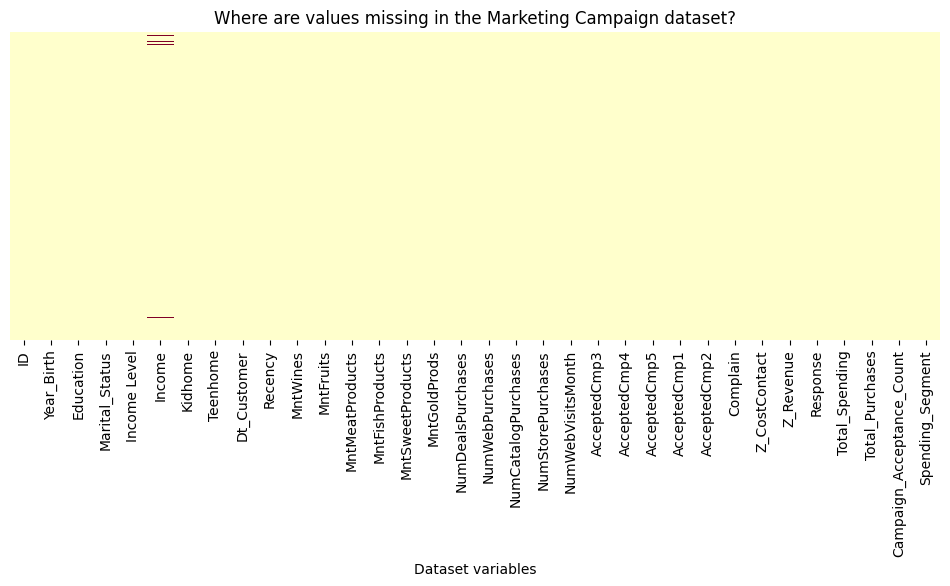

In [ ]:
# Missingness heatmap (only if missing values exist)
plt.figure(figsize=(12, 4))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="YlOrRd")
plt.title("Where are values missing in the Marketing Campaign dataset?")
plt.xlabel("Dataset variables")
plt.show()

Outliers, IQR and distribution checks

In [ ]:
# IQR summary for selected variables
outlier_cols = ["Income", "Total_Spending", "Recency", "NumWebVisitsMonth"]
iqr_rows = []
for col in outlier_cols:
    series = df[col].dropna()
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((series < lower) | (series > upper)).sum()
    iqr_rows.append([col, q1, q3, iqr, lower, upper, int(count)])
iqr_table = pd.DataFrame(iqr_rows, columns=["Variable", "Q1", "Q3", "IQR", "Lower fence", "Upper fence", "Flagged count"])
display(iqr_table.round(2))

,Variable,Q1,Q3,IQR,Lower fence,Upper fence,Flagged count
0,Income,35303.00,68522.0,33219.00,-14525.50,118350.50,8
1,Total_Spending,68.75,1045.5,976.75,-1396.38,2510.62,3
2,Recency,24.00,74.0,50.00,-51.00,149.00,0
3,NumWebVisitsMonth,3.00,7.0,4.00,-3.00,13.00,8


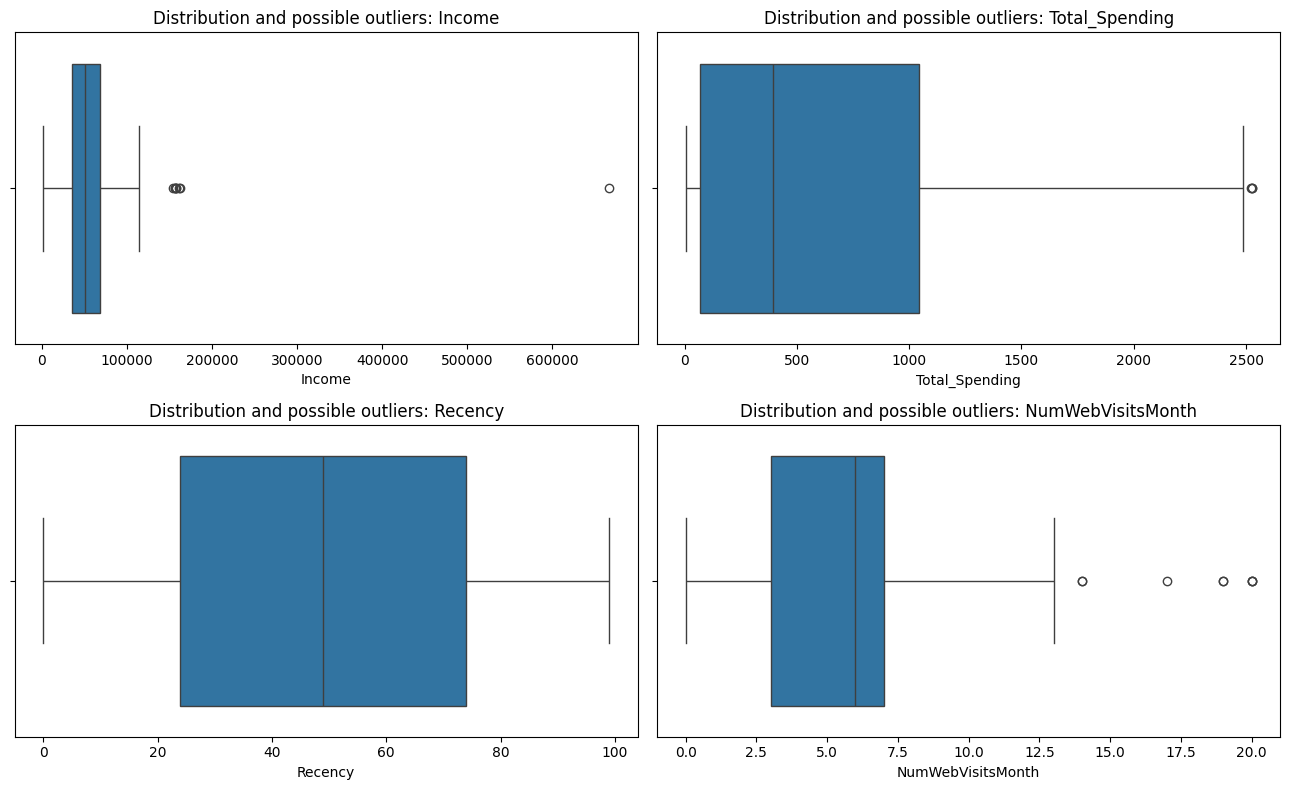

In [ ]:
# Box plots to inspect flagged values visually
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, outlier_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Distribution and possible outliers: {col}")
plt.tight_layout()
plt.show()

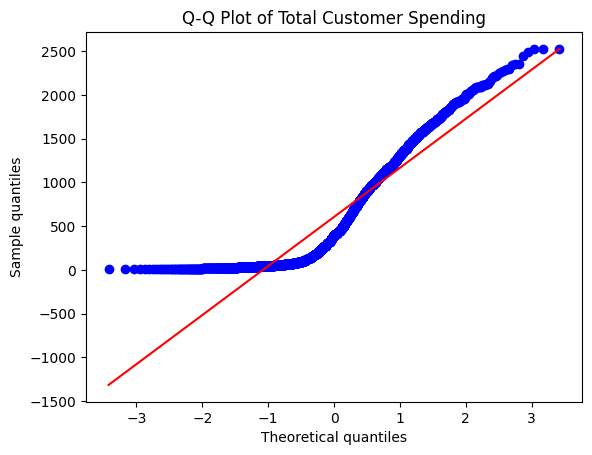

In [ ]:
# Q-Q plot for total spending (drop missing values only for this plot)
from scipy import stats
spend_for_qq = df["Total_Spending"].dropna()
stats.probplot(spend_for_qq, dist="norm", plot=plt)
plt.title("Q-Q Plot of Total Customer Spending")
plt.xlabel("Theoretical quantiles")
plt.ylabel("Sample quantiles")
plt.show()

In [ ]:
# Example: inspect high-income and high-spending observations before deciding
display(df.nlargest(10, "Income")[["ID", "Income", "Total_Spending", "Education", "Marital_Status"]])
display(df.nlargest(10, "Total_Spending")[["ID", "Income", "Total_Spending", "Education", "Marital_Status"]])


,ID,Income,Total_Spending,Education,Marital_Status
2233,9432,666666.0,62,Graduation,Together
617,1503,162397.0,107,PhD,Together
687,1501,160803.0,1717,PhD,Married
1300,5336,157733.0,59,Master,Together
164,8475,157243.0,1608,PhD,Married
1653,4931,157146.0,1730,Graduation,Together
2132,11181,156924.0,8,PhD,Married
655,5555,153924.0,6,Graduation,Divorced
1898,4619,113734.0,277,PhD,Single
646,4611,105471.0,1724,Graduation,Together


,ID,Income,Total_Spending,Education,Marital_Status
1179,5735,90638.0,2525,Master,Single
1572,5350,90638.0,2525,Master,Single
1492,1763,87679.0,2524,Graduation,Together
987,4580,75759.0,2486,Graduation,Married
1052,4475,69098.0,2440,PhD,Married
1601,5453,90226.0,2352,Master,Married
1458,10133,93790.0,2349,Graduation,Single
1288,9010,83151.0,2346,Master,Married
943,5386,94384.0,2302,Graduation,Together
1301,6024,94384.0,2302,Graduation,Together


Treatment of missing values and group-wise summaries

In [ ]:
# Compare common missing-value treatment methods for Income
print("Missing Income values:", df["Income"].isna().sum())
print("Income mean:", round(df["Income"].mean(), 2))
print("Income median:", round(df["Income"].median(), 2))
print("Income mode:", round(df["Income"].mode().iloc[0], 2))

df_drop_income = df.dropna(subset=["Income"]).copy()
df_mean_income = df.copy(); df_mean_income["Income"] = df_mean_income["Income"].fillna(df_mean_income["Income"].mean())
df_median_income = df.copy(); df_median_income["Income"] = df_median_income["Income"].fillna(df_median_income["Income"].median())
df_mode_income = df.copy(); df_mode_income["Income"] = df_mode_income["Income"].fillna(df_mode_income["Income"].mode().iloc[0])
print("Rows after dropna:", len(df_drop_income))
print("Missing after mean/median/mode:", df_mean_income["Income"].isna().sum(), df_median_income["Income"].isna().sum(), df_mode_income["Income"].isna().sum())

Missing Income values: 24
Income mean: 52247.25
Income median: 51381.5
Income mode: 7500.0
Rows after dropna: 2216
Missing after mean/median/mode: 0 0 0


In [ ]:
# Compare the income distributions after each treatment
comparison = pd.DataFrame({
    "Original available": df["Income"].dropna().describe(),
    "Drop rows": df_drop_income["Income"].describe(),
    "Mean imputation": df_mean_income["Income"].describe(),
    "Median imputation": df_median_income["Income"].describe(),
    "Mode imputation": df_mode_income["Income"].describe()
})
display(comparison.round(2))

,Original available,Drop rows,Mean imputation,Median imputation,Mode imputation
count,2216.00,2216.00,2240.00,2240.00,2240.00
mean,52247.25,52247.25,52247.25,52237.98,51767.82
std,25173.08,25173.08,25037.80,25037.96,25458.29
min,1730.00,1730.00,1730.00,1730.00,1730.00
25%,35303.00,35303.00,35538.75,35538.75,34722.00
50%,51381.50,51381.50,51741.50,51381.50,51075.00
75%,68522.00,68522.00,68289.75,68289.75,68289.75
max,666666.00,666666.00,666666.00,666666.00,666666.00


In [ ]:
# Create the working dataset using median imputation for missing Income
# This is a transparent analytical choice; the raw data remains unchanged.
clean_df = df_median_income.copy()
clean_df = clean_df.drop_duplicates().copy()
clean_df["Dt_Customer"] = pd.to_datetime(clean_df["Dt_Customer"], errors="coerce")

# Derived variables used in business questions
clean_df["Total_Spending"] = clean_df[spending_cols].sum(axis=1)
clean_df["Total_Purchases"] = clean_df[channel_cols].sum(axis=1)
clean_df["Campaign_Acceptance_Count"] = clean_df[campaign_cols].sum(axis=1)
clean_df["Any_Previous_Campaign_Accepted"] = (clean_df["Campaign_Acceptance_Count"] > 0).astype(int)
print("Clean dataset shape:", clean_df.shape)
print("Remaining missing Income:", clean_df["Income"].isna().sum())

Clean dataset shape: (2240, 35)
Remaining missing Income: 0


In [ ]:
# Recalculate spending bands and inspect group-wise summaries (Business Question 1)
clean_df["Spending_Segment"] = pd.qcut(clean_df["Total_Spending"].rank(method="first"), 3, labels=["Low", "Medium", "High"])
segment_summary = clean_df.groupby("Income Level", observed=False)["Total_Spending"].agg(["count", "mean", "median", "sum"]).sort_values("mean", ascending=False)
display(segment_summary.round(2))
print("Interpretation: the group with the highest mean/total spending is the leading group in this sample; check group sizes too.")

,count,mean,median,sum
Income Level,,,,
High Income,288,1472.35,1497.0,424036
Middle Income,1632,551.65,400.5,900294
Low Income,320,102.06,50.0,32658


Interpretation: the group with the highest mean/total spending is the leading group in this sample; check group sizes too.


In [ ]:
# Group-wise summaries by education and marital status (Business Question 1)
education_spend = clean_df.groupby("Education")["Total_Spending"].agg(["count", "mean", "median", "sum"]).sort_values("mean", ascending=False)
marital_spend = clean_df.groupby("Marital_Status")["Total_Spending"].agg(["count", "mean", "median", "sum"]).sort_values("mean", ascending=False)
display(education_spend.round(2))
display(marital_spend.round(2))

,count,mean,median,sum
Education,,,,
PhD,486,672.41,493.0,326791
Graduation,1127,619.90,414.0,698626
Master,370,611.78,387.5,226359
2n Cycle,203,496.53,198.0,100795
Basic,54,81.80,57.0,4417


,count,mean,median,sum
Marital_Status,,,,
Absurd,2,1192.50,1192.5,2385
Widow,77,738.82,636.0,56889
Divorced,232,610.63,395.0,141666
Together,580,608.39,393.5,352865
Single,480,606.48,361.0,291112
Married,864,590.80,396.5,510453
YOLO,2,424.00,424.0,848
Alone,3,256.67,89.0,770


Core visualisation: histogram, scatter, line, area, bar, count, box, violin and pair plots

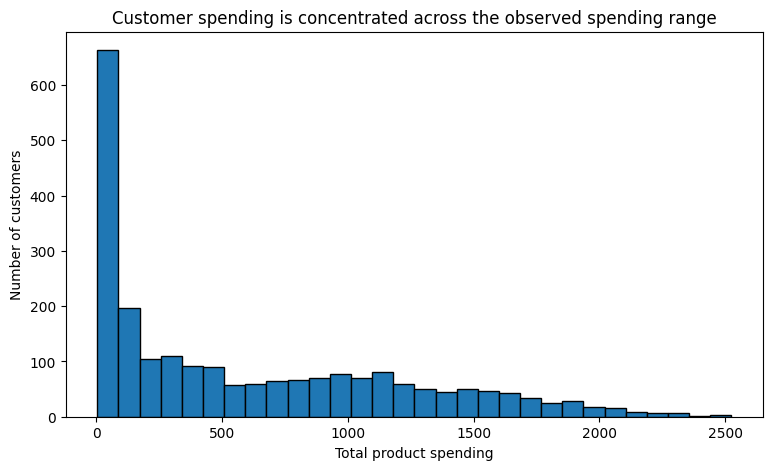

In [ ]:
# Histogram: how is customer spending distributed?
plt.figure(figsize=(9, 5))
plt.hist(clean_df["Total_Spending"].dropna(), bins=30, edgecolor="black")
plt.title("Customer spending is concentrated across the observed spending range")
plt.xlabel("Total product spending")
plt.ylabel("Number of customers")
plt.show()

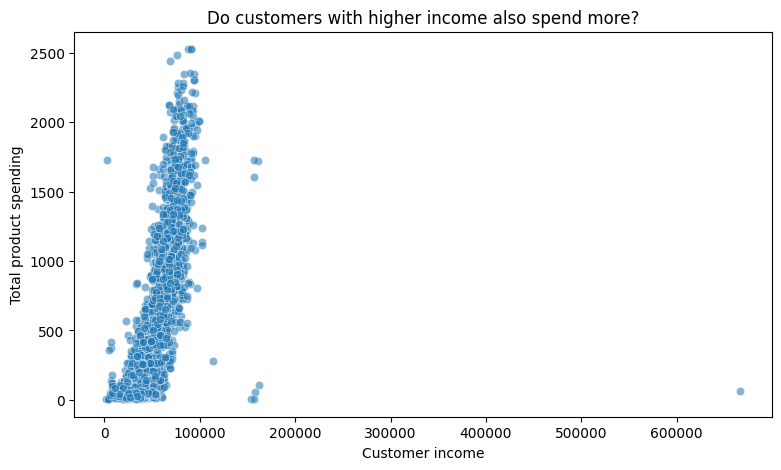

In [ ]:
# Scatter plot: income versus total spending (Business Question 3)
plt.figure(figsize=(9, 5))
sns.scatterplot(data=clean_df, x="Income", y="Total_Spending", alpha=0.55)
plt.title("Do customers with higher income also spend more?")
plt.xlabel("Customer income")
plt.ylabel("Total product spending")
plt.show()

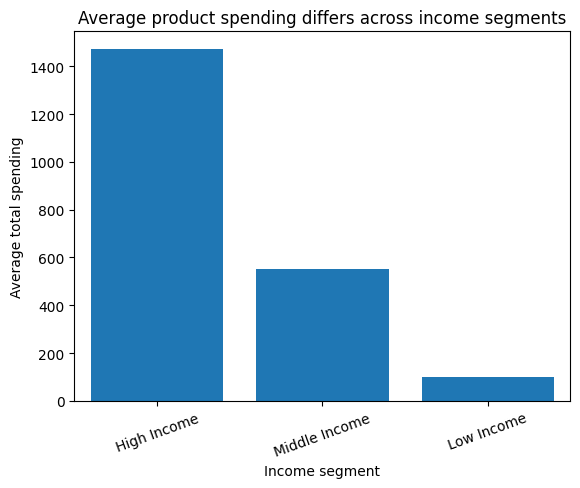

In [ ]:
# Bar chart: average spending by income segment (Business Question 1)
inc_order = clean_df.groupby("Income Level")["Total_Spending"].mean().sort_values(ascending=False).index
sns.barplot(saturation=1, data=clean_df, x="Income Level", y="Total_Spending", order=inc_order, estimator=np.mean, errorbar=None)
plt.title("Average product spending differs across income segments")
plt.xlabel("Income segment")
plt.ylabel("Average total spending")
plt.xticks(rotation=20)
plt.show()

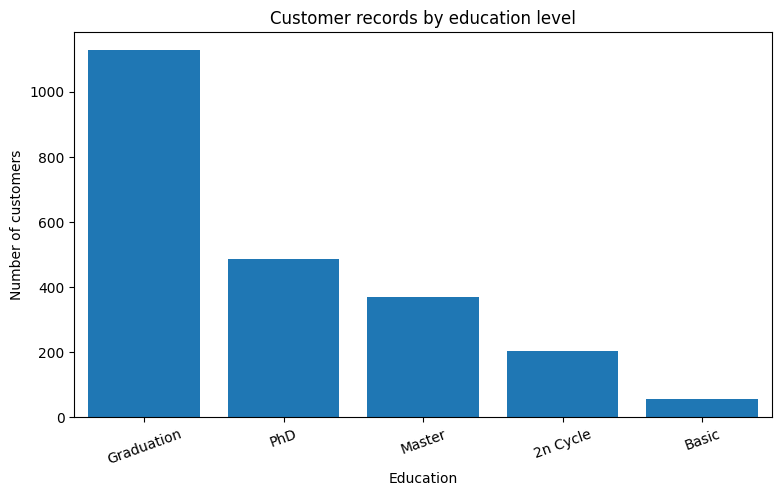

In [ ]:
# Count plot: customer counts by education
plt.figure(figsize=(9, 5))
sns.countplot(saturation=1, data=clean_df, x="Education", order=clean_df["Education"].value_counts().index)
plt.title("Customer records by education level")
plt.xlabel("Education")
plt.ylabel("Number of customers")
plt.xticks(rotation=20)
plt.show()

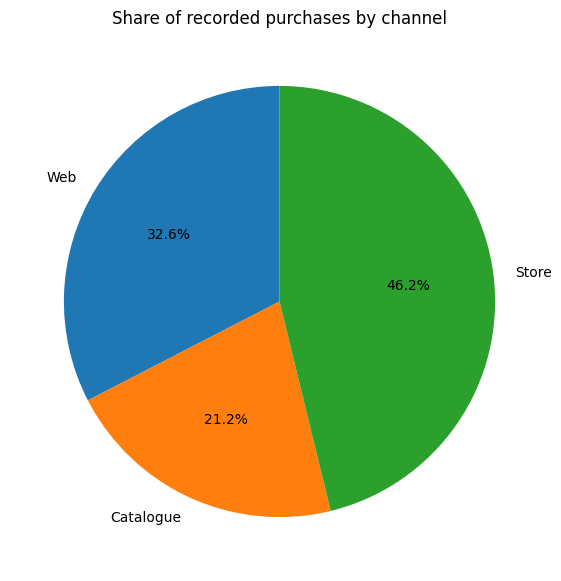

,Total purchases
NumWebPurchases,9150
NumCatalogPurchases,5963
NumStorePurchases,12970


In [ ]:
# Pie chart: share of purchases by channel (Business Question 2)
channel_totals = clean_df[channel_cols].sum()
plt.figure(figsize=(7, 7))
plt.pie(channel_totals.values, labels=["Web", "Catalogue", "Store"], autopct="%1.1f%%", startangle=90)
plt.title("Share of recorded purchases by channel")
plt.show()
display(channel_totals.rename("Total purchases").to_frame())

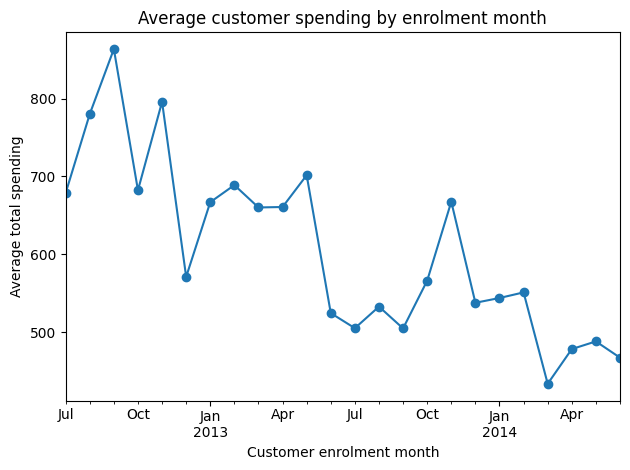

In [ ]:
# Line plot: average spending by customer enrolment month
monthly_spend = clean_df.dropna(subset=["Dt_Customer"]).assign(Join_Month=lambda x: x["Dt_Customer"].dt.to_period("M").dt.to_timestamp()).groupby("Join_Month")["Total_Spending"].mean()
monthly_spend.plot(marker="o")
plt.title("Average customer spending by enrolment month")
plt.xlabel("Customer enrolment month")
plt.ylabel("Average total spending")
plt.tight_layout(); plt.show()

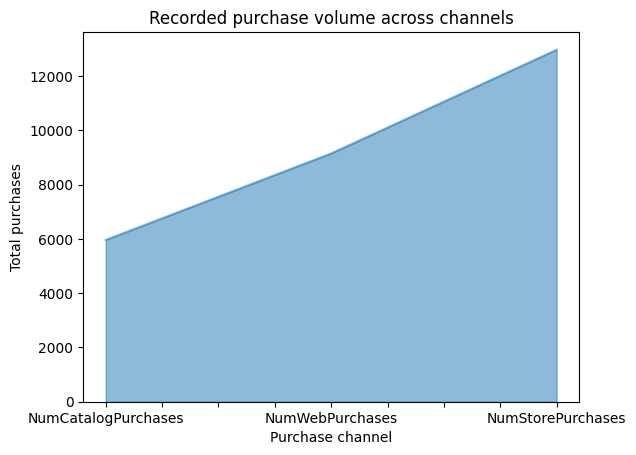

In [ ]:
# Area plot: cumulative purchase-channel totals by channel
channel_totals.sort_values().plot(kind="area", alpha=0.5)
plt.title("Recorded purchase volume across channels")
plt.xlabel("Purchase channel")
plt.ylabel("Total purchases")
plt.show()

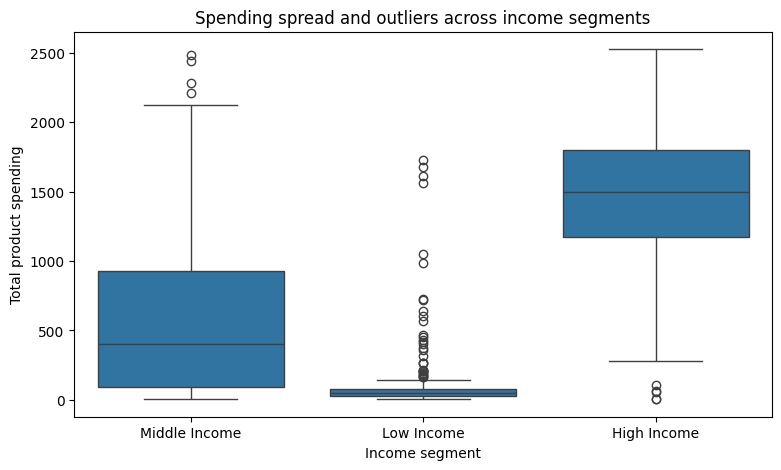

In [ ]:
# Box plot: spending differences by income segment
plt.figure(figsize=(9, 5))
sns.boxplot(data=clean_df, x="Income Level", y="Total_Spending")
plt.title("Spending spread and outliers across income segments")
plt.xlabel("Income segment"); plt.ylabel("Total product spending")
plt.show()

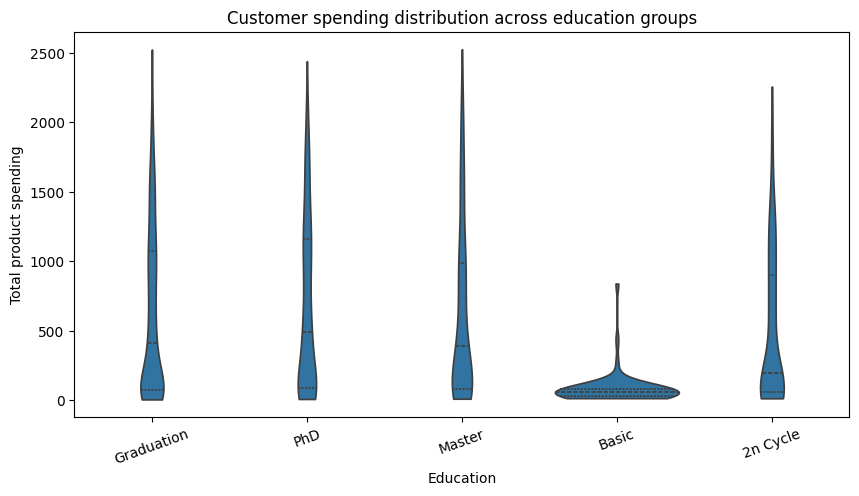

In [ ]:
# Violin plot: spending distribution by education
plt.figure(figsize=(10, 5))
sns.violinplot(data=clean_df, x="Education", y="Total_Spending", inner="quartile", cut=0)
plt.title("Customer spending distribution across education groups")
plt.xlabel("Education"); plt.ylabel("Total product spending")
plt.xticks(rotation=20); plt.show()

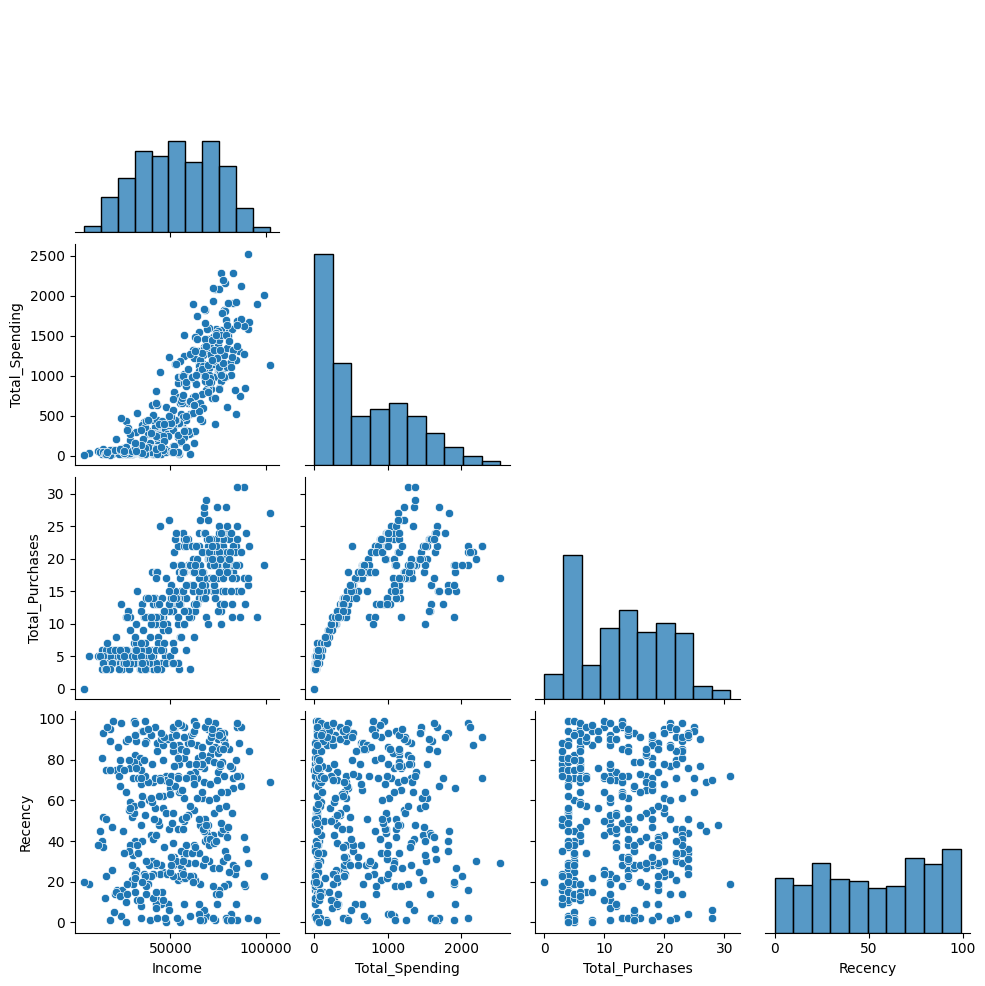

In [ ]:
# Pair plot: relationships among a small set of key numerical variables
pair_sample = clean_df[["Income", "Total_Spending", "Total_Purchases", "Recency"]].dropna().sample(min(400, clean_df.dropna(subset=["Income"]).shape[0]), random_state=42)
sns.pairplot(pair_sample, corner=True, diag_kind="hist")
plt.show()

Additional visualisation and chart choice

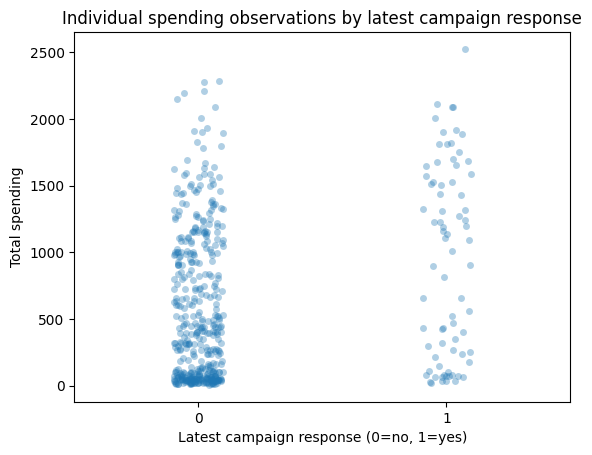

In [ ]:
# Strip plot: show individual customer spending values by campaign response
plot_sample = clean_df.sample(min(500, len(clean_df)), random_state=42)
sns.stripplot(data=plot_sample, x="Response", y="Total_Spending", alpha=0.35, jitter=True)
plt.title("Individual spending observations by latest campaign response")
plt.xlabel("Latest campaign response (0=no, 1=yes)"); plt.ylabel("Total spending")
plt.show()

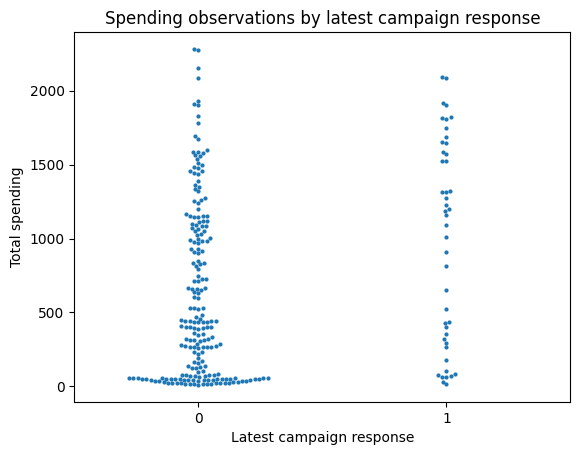

In [ ]:
# Swarm plot: individual observations (sampled for readability)
swarm_sample = clean_df.sample(min(250, len(clean_df)), random_state=42)
sns.swarmplot(data=swarm_sample, x="Response", y="Total_Spending", size=3)
plt.title("Spending observations by latest campaign response")
plt.xlabel("Latest campaign response"); plt.ylabel("Total spending")
plt.show()

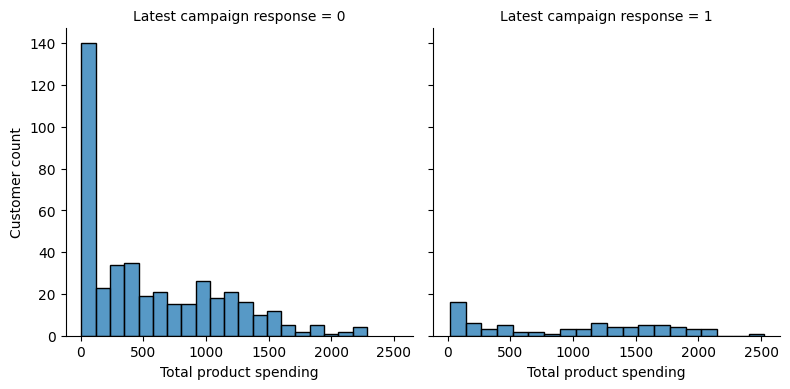

In [ ]:
# FacetGrid: spending distribution separated by latest campaign response
g = sns.FacetGrid(plot_sample, col="Response", height=4, sharex=True, sharey=True)
g.map_dataframe(sns.histplot, x="Total_Spending", bins=20)
g.set_axis_labels("Total product spending", "Customer count")
g.set_titles("Latest campaign response = {col_name}")
plt.show()

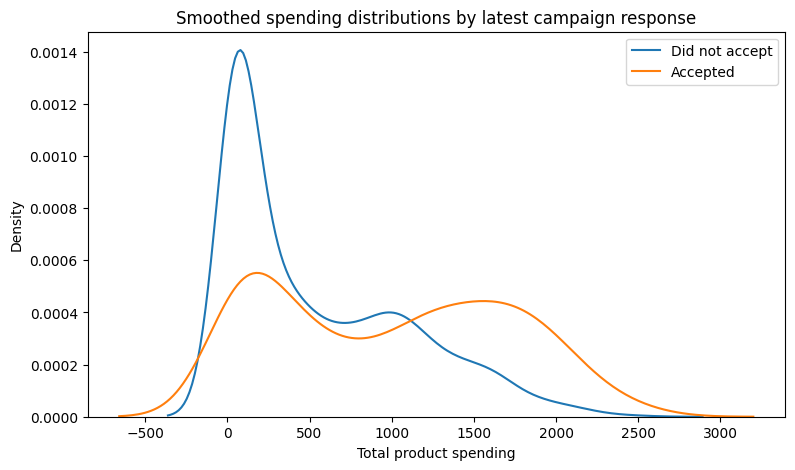

In [ ]:
# KDE: smoothed spending distributions for responders and non-responders
plt.figure(figsize=(9, 5))
for response_value, label in [(0, "Did not accept"), (1, "Accepted")]:
    sns.kdeplot(data=clean_df.loc[clean_df["Response"] == response_value, "Total_Spending"], label=label, fill=False)
plt.title("Smoothed spending distributions by latest campaign response")
plt.xlabel("Total product spending"); plt.ylabel("Density")
plt.legend(); plt.show()

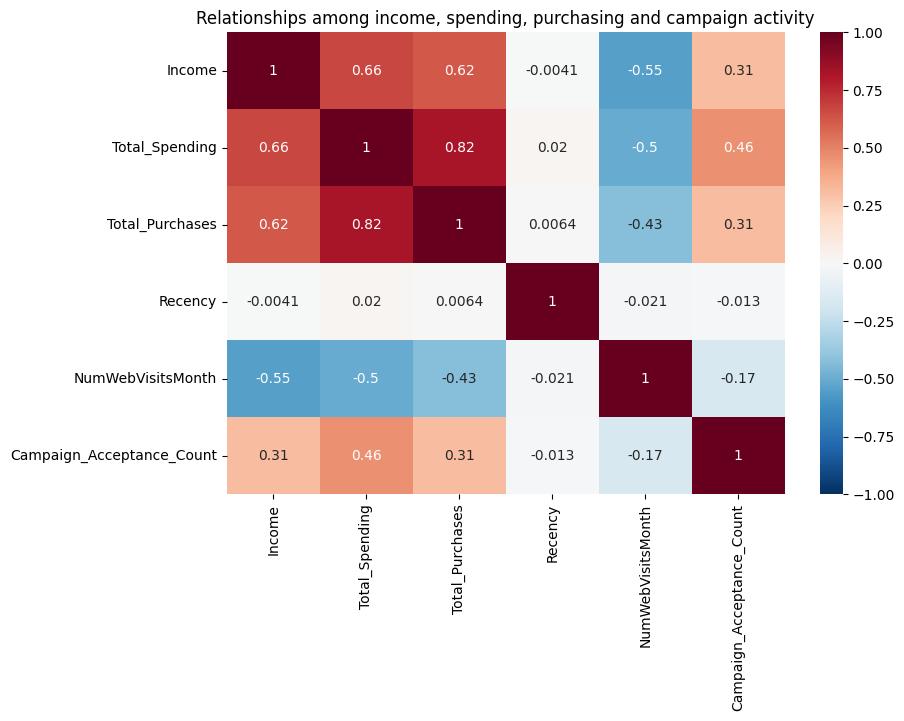

In [ ]:
# Heatmap: correlation among key numeric variables
key_numeric = ["Income", "Total_Spending", "Total_Purchases", "Recency", "NumWebVisitsMonth", "Campaign_Acceptance_Count"]
corr_matrix = clean_df[key_numeric].corr(numeric_only=True)
plt.figure(figsize=(9, 6))
sns.heatmap(corr_matrix, annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Relationships among income, spending, purchasing and campaign activity")
plt.show()

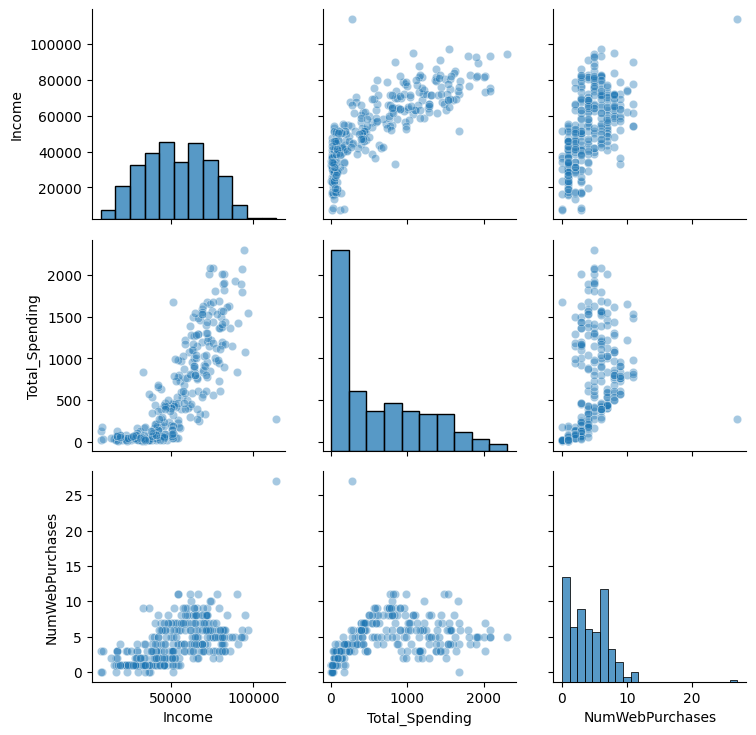

In [ ]:
# PairGrid: a second pairwise view using a smaller random sample
pg_data = clean_df[["Income", "Total_Spending", "NumWebPurchases"]].dropna().sample(min(300, clean_df.dropna(subset=["Income"]).shape[0]), random_state=7)
grid = sns.PairGrid(pg_data)
grid.map_diag(sns.histplot)
grid.map_offdiag(sns.scatterplot, alpha=0.4)
plt.show()

Advanced Matplotlib, annotations, subplots.

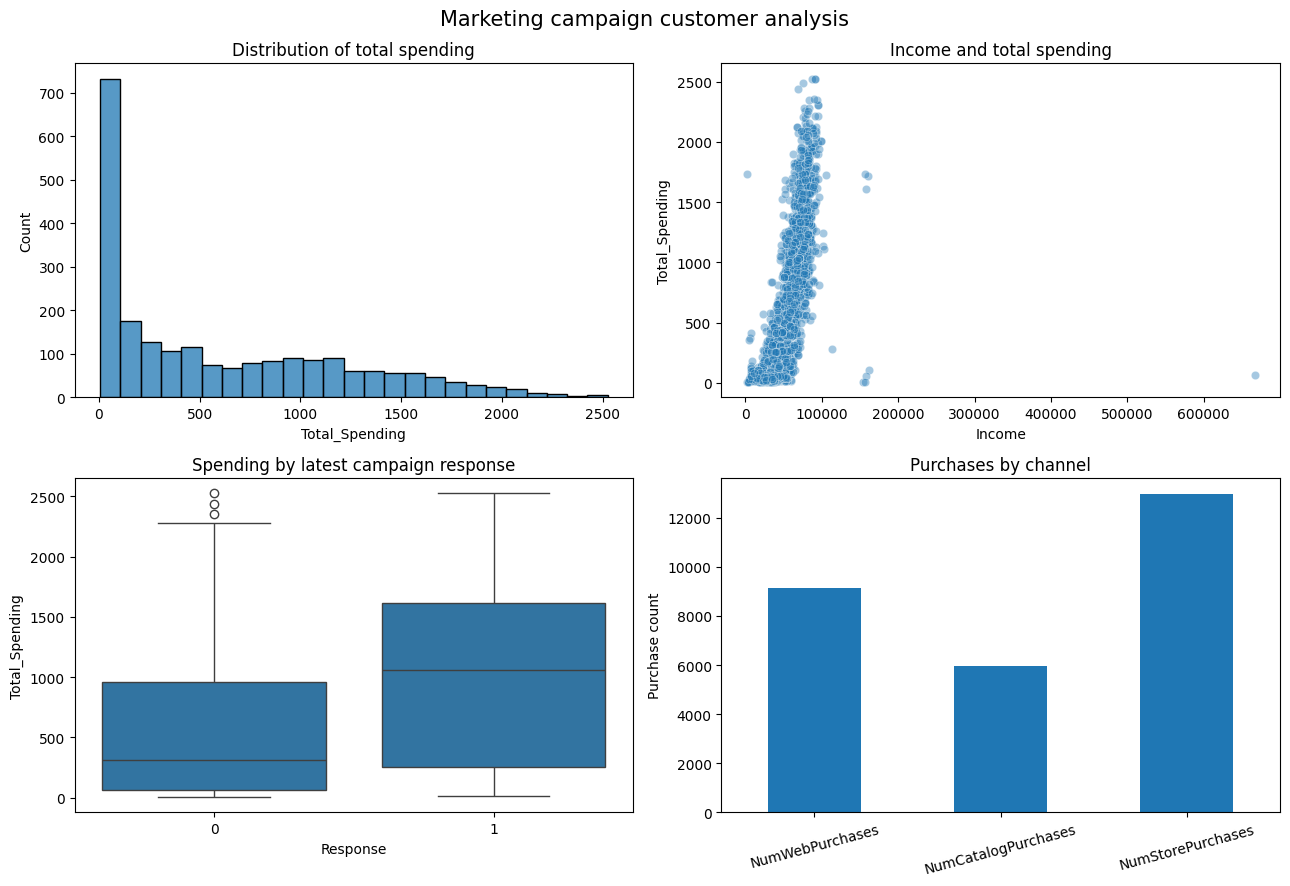

In [ ]:
# Multi-panel chart with business annotations
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.histplot(clean_df["Total_Spending"], bins=25, ax=axes[0,0])
axes[0,0].set_title("Distribution of total spending")
sns.scatterplot(data=clean_df, x="Income", y="Total_Spending", alpha=0.4, ax=axes[0,1])
axes[0,1].set_title("Income and total spending")
sns.boxplot(data=clean_df, x="Response", y="Total_Spending", ax=axes[1,0])
axes[1,0].set_title("Spending by latest campaign response")
channel_totals.plot(kind="bar", ax=axes[1,1])
axes[1,1].set_title("Purchases by channel"); axes[1,1].set_ylabel("Purchase count")
axes[1,1].tick_params(axis="x", rotation=15)
fig.suptitle("Marketing campaign customer analysis", fontsize=15)
plt.tight_layout(); plt.show()

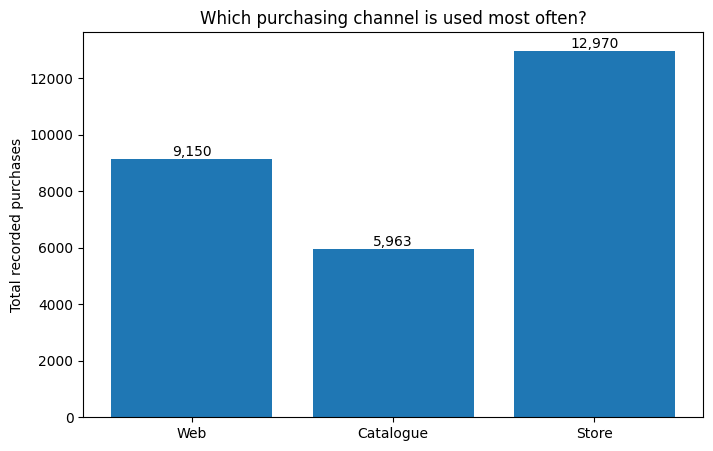

In [ ]:
# Annotated bar chart: channel volumes (Business Question 2)
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(["Web", "Catalogue", "Store"], [channel_totals[c] for c in channel_cols])
ax.set_title("Which purchasing channel is used most often?")
ax.set_ylabel("Total recorded purchases")
for bar in bars:
    ax.annotate(f"{bar.get_height():,.0f}", (bar.get_x()+bar.get_width()/2, bar.get_height()),
                ha="center", va="bottom")
plt.show()

Map / geographic visualisation - not applicable

Business-focused categorical plots and time/cohort views

Here we compare marketing campaign responses, income groups, education and enrolment cohorts. These views support Business Questions 1, 2 and 4.

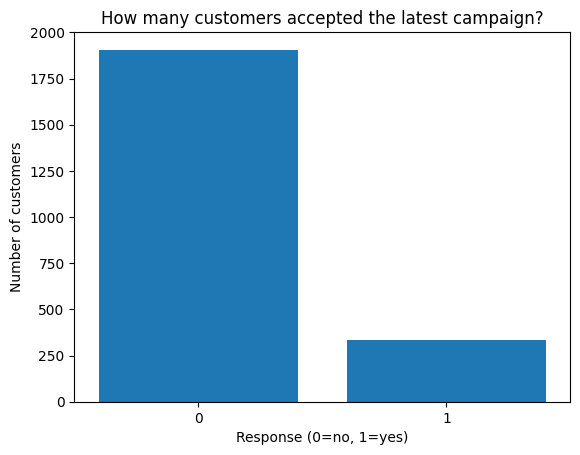

In [ ]:
# Count plot: latest campaign responses
sns.countplot(saturation=1, data=clean_df, x="Response")
plt.title("How many customers accepted the latest campaign?")
plt.xlabel("Response (0=no, 1=yes)"); plt.ylabel("Number of customers")
plt.show()

,mean,count,Response_Rate_Pct
Education,,,
PhD,0.21,486,20.78
Master,0.15,370,15.41
Graduation,0.13,1127,13.49
2n Cycle,0.11,203,10.84
Basic,0.04,54,3.70


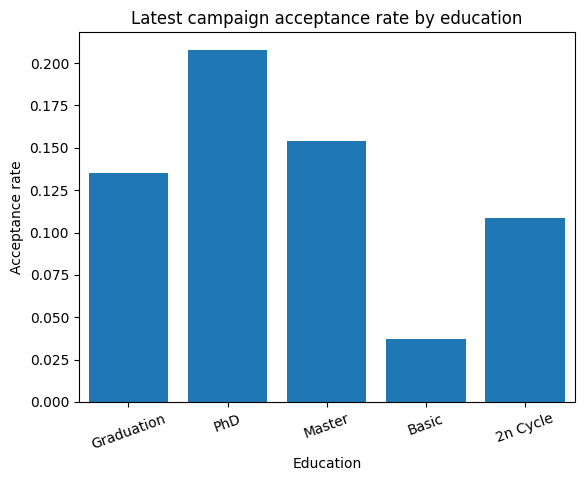

In [ ]:
# Response rate by education (Business Question 4)
response_education = clean_df.groupby("Education")["Response"].agg(["mean", "count"]).sort_values("mean", ascending=False)
response_education["Response_Rate_Pct"] = response_education["mean"] * 100
display(response_education.round(2))
sns.barplot(saturation=1, data=clean_df, x="Education", y="Response", estimator=np.mean, errorbar=None)
plt.title("Latest campaign acceptance rate by education")
plt.ylabel("Acceptance rate"); plt.xlabel("Education")
plt.xticks(rotation=20); plt.show()

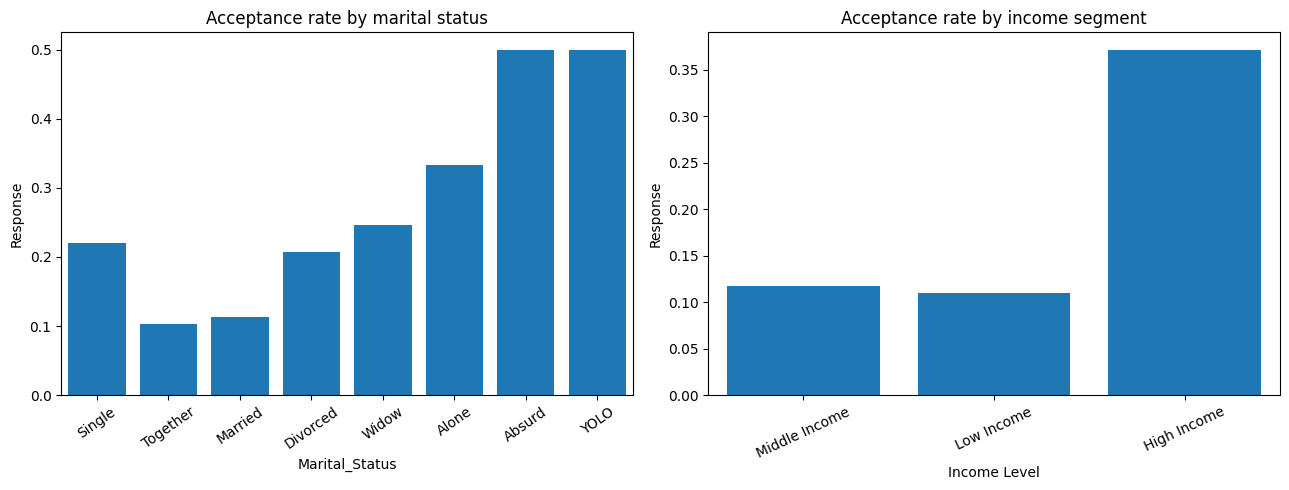

In [ ]:
# Response rate by marital status and income level (Business Question 4)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(saturation=1, data=clean_df, x="Marital_Status", y="Response", estimator=np.mean, errorbar=None, ax=axes[0])
axes[0].set_title("Acceptance rate by marital status"); axes[0].tick_params(axis="x", rotation=35)
sns.barplot(saturation=1, data=clean_df, x="Income Level", y="Response", estimator=np.mean, errorbar=None, ax=axes[1])
axes[1].set_title("Acceptance rate by income segment"); axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

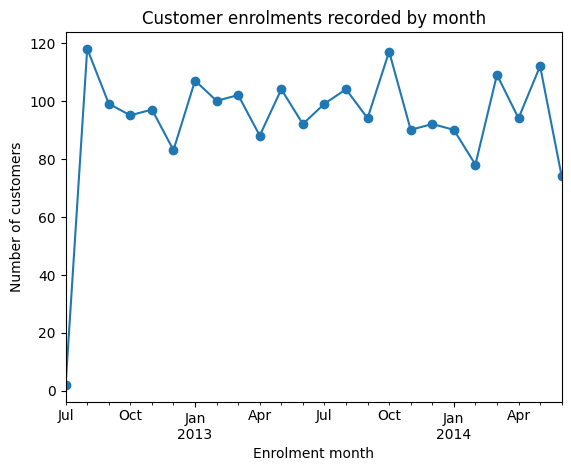

In [ ]:
# Enrolment cohort trend: customer counts by month
cohort_counts = clean_df.dropna(subset=["Dt_Customer"]).assign(Join_Month=lambda x: x["Dt_Customer"].dt.to_period("M").dt.to_timestamp()).groupby("Join_Month").size()
cohort_counts.plot(kind="line", marker="o")
plt.title("Customer enrolments recorded by month")
plt.xlabel("Enrolment month"); plt.ylabel("Number of customers")
plt.show()

#Correlation and relationships between variables

Correlation measures the direction and strength of a linear association. It does not prove that one variable causes another. We calculate the income–spending relationship and inspect a heatmap of the key numerical measures.

In [ ]:
# Correlations relevant to the business questions
pairs = [("Income", "Total_Spending"), ("NumWebVisitsMonth", "NumWebPurchases"),
         ("Recency", "Response"), ("Total_Spending", "Campaign_Acceptance_Count")]
for x, y in pairs:
    r = clean_df[x].corr(clean_df[y])
    print(f"Correlation between {x} and {y}: {r:.3f}")

Correlation between Income and Total_Spending: 0.665
Correlation between NumWebVisitsMonth and NumWebPurchases: -0.056
Correlation between Recency and Response: -0.198
Correlation between Total_Spending and Campaign_Acceptance_Count: 0.460


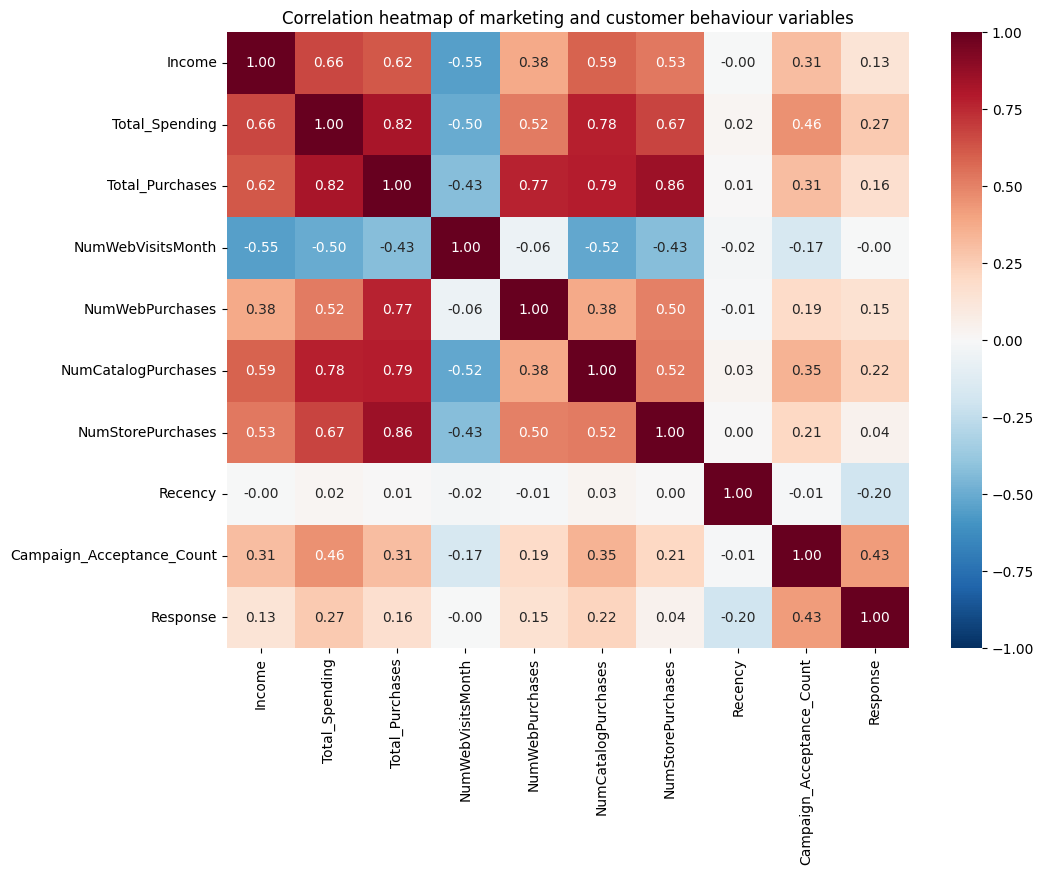

In [ ]:
# Correlation matrix and heatmap
correlation_cols = ["Income", "Total_Spending", "Total_Purchases", "NumWebVisitsMonth",
                    "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases",
                    "Recency", "Campaign_Acceptance_Count", "Response"]
corr = clean_df[correlation_cols].corr(numeric_only=True)
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation heatmap of marketing and customer behaviour variables")
plt.show()

How to interpret: A positive coefficient means the two variables tend to move in the same direction; a negative coefficient means they tend to move in opposite directions. A value close to zero indicates a weak linear association. Check sample size and outliers, and do not write that income causes spending based on correlation alone.

#Simple and multiple linear regression

Regression estimates how the outcome variable changes with one or more predictors. Business Question 3 is answered with total product spending as the outcome and income as the main predictor. A second model controls for other customer characteristics. These are associations, not causal effects.

In [ ]:
import statsmodels.formula.api as smf

reg_data = clean_df[["Income", "Total_Spending"]].dropna()
simple_model = smf.ols("Total_Spending ~ Income", data=reg_data).fit()
print(simple_model.summary())
print("R-squared:", round(simple_model.rsquared, 3))
print("Income coefficient:", round(simple_model.params["Income"], 5))
print("Income p-value:", simple_model.pvalues["Income"])

                            OLS Regression Results                            
Dep. Variable:         Total_Spending   R-squared:                       0.442
Model:                            OLS   Adj. R-squared:                  0.442
Method:                 Least Squares   F-statistic:                     1772.
Date:                Mon, 16 Nov 2026   Prob (F-statistic):          8.96e-286
Time:                        17:17:12   Log-Likelihood:                -16862.
No. Observations:                2240   AIC:                         3.373e+04
Df Residuals:                    2238   BIC:                         3.374e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   -229.4938     22.002    -10.430      0.0

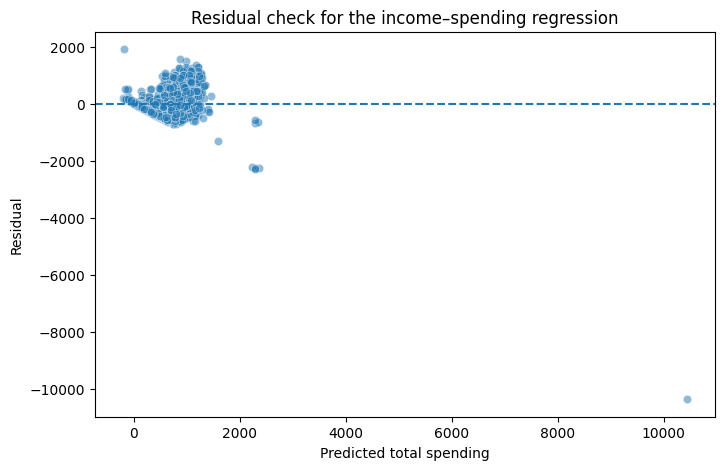

In [ ]:
# Regression diagnostic: residuals versus fitted values
plt.figure(figsize=(8, 5))
sns.scatterplot(x=simple_model.fittedvalues, y=simple_model.resid, alpha=.5)
plt.axhline(0, linestyle="--")
plt.title("Residual check for the income–spending regression")
plt.xlabel("Predicted total spending"); plt.ylabel("Residual")
plt.show()

In [ ]:
# Multiple regression: add age proxy, recency, household and channel behaviour
# Year_Birth is converted into an approximate age using a fixed 2014 reference year.
# The dataset does not provide an exact age-at-purchase field.
reg_df = clean_df.copy()
reg_df["Approx_Age_2014"] = 2014 - reg_df["Year_Birth"]
reg_cols = ["Total_Spending", "Income", "Approx_Age_2014", "Recency", "Kidhome", "Teenhome", "NumWebVisitsMonth"]
reg_df = reg_df[reg_cols].replace([np.inf, -np.inf], np.nan).dropna()
multi_model = smf.ols("Total_Spending ~ Income + Approx_Age_2014 + Recency + Kidhome + Teenhome + NumWebVisitsMonth", data=reg_df).fit()
print(multi_model.summary())
print("Multiple-model R-squared:", round(multi_model.rsquared, 3))

                            OLS Regression Results                            
Dep. Variable:         Total_Spending   R-squared:                       0.562
Model:                            OLS   Adj. R-squared:                  0.561
Method:                 Least Squares   F-statistic:                     478.3
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        17:18:24   Log-Likelihood:                -16590.
No. Observations:                2240   AIC:                         3.319e+04
Df Residuals:                    2233   BIC:                         3.323e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept           275.5961     54.08

In [ ]:
# Example prediction for a customer profile using the fitted multiple regression
example_customer = pd.DataFrame({"Income": [50000], "Approx_Age_2014": [40], "Recency": [30],
                                  "Kidhome": [1], "Teenhome": [0], "NumWebVisitsMonth": [5]})
predicted_spend = multi_model.predict(example_customer).iloc[0]
print("Illustrative predicted spending:", round(predicted_spend, 2))
print("This is a model estimate, not a guaranteed customer outcome.")

Illustrative predicted spending: 457.1
This is a model estimate, not a guaranteed customer outcome.


Multiple regression, moderation / interaction effect and PCA

In [ ]:
# Does income remain associated with spending after controlling for web visits?
model_income_alone = smf.ols("Total_Spending ~ Income", data=clean_df).fit()
model_income_control = smf.ols("Total_Spending ~ Income + NumWebVisitsMonth", data=clean_df).fit()
print("Income coefficient alone:", round(model_income_alone.params["Income"], 5),
      "| p-value:", round(model_income_alone.pvalues["Income"], 4))
print("Income coefficient with web visits:", round(model_income_control.params["Income"], 5),
      "| p-value:", round(model_income_control.pvalues["Income"], 4))
print("R-squared alone:", round(model_income_alone.rsquared, 3),
      "| controlled:", round(model_income_control.rsquared, 3))

Income coefficient alone: 0.01599 | p-value: 0.0
Income coefficient with web visits: 0.01344 | p-value: 0.0
R-squared alone: 0.442 | controlled: 0.468


In [ ]:
# Moderation / interaction: does the income-spending association vary with web visits?
moderation_df = clean_df[["Income", "NumWebVisitsMonth", "Total_Spending"]].dropna().copy()
moderation_df["Income_c"] = moderation_df["Income"] - moderation_df["Income"].mean()
moderation_df["WebVisits_c"] = moderation_df["NumWebVisitsMonth"] - moderation_df["NumWebVisitsMonth"].mean()
moderation_model = smf.ols("Total_Spending ~ Income_c * WebVisits_c", data=moderation_df).fit()
print(moderation_model.summary())
print("Interaction coefficient:", moderation_model.params["Income_c:WebVisits_c"])
print("Interaction p-value:", moderation_model.pvalues["Income_c:WebVisits_c"])

                            OLS Regression Results                            
Dep. Variable:         Total_Spending   R-squared:                       0.478
Model:                            OLS   Adj. R-squared:                  0.477
Method:                 Least Squares   F-statistic:                     681.7
Date:                Mon, 16 Nov 2026   Prob (F-statistic):          1.12e-314
Time:                        17:22:06   Log-Likelihood:                -16788.
No. Observations:                2240   AIC:                         3.358e+04
Df Residuals:                    2236   BIC:                         3.361e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept              574.5525 

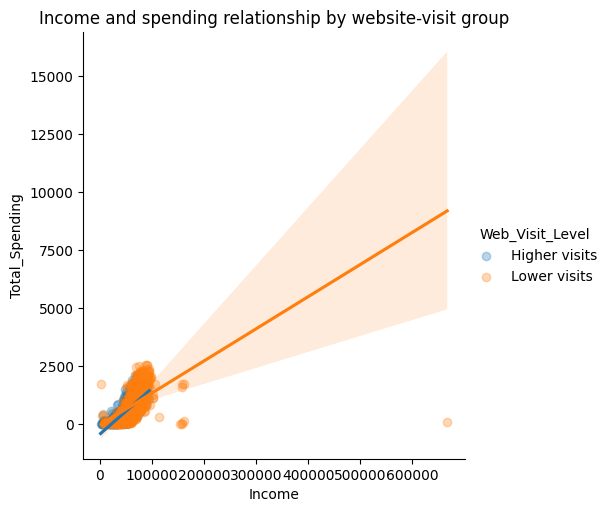

In [ ]:
# Visualise interaction using low/high website visit groups
moderation_df["Web_Visit_Level"] = np.where(moderation_df["NumWebVisitsMonth"] > moderation_df["NumWebVisitsMonth"].median(), "Higher visits", "Lower visits")
g = sns.lmplot(data=moderation_df, x="Income", y="Total_Spending", hue="Web_Visit_Level", height=5, scatter_kws={"alpha": .3})
g.set(title="Income and spending relationship by website-visit group")
plt.show()

#FINAL BUSINESS QUESTION ANSWER SHEET

In [ ]:
# Compact results for the five business questions
print("BUSINESS QUESTION 1 — Highest-spending segments")
q1 = clean_df.groupby("Income Level")["Total_Spending"].agg(["count", "mean", "sum"]).sort_values("mean", ascending=False)
display(q1.round(2))

print("BUSINESS QUESTION 2 — Most-used purchasing channel")
q2 = channel_totals.sort_values(ascending=False)
display(q2.to_frame("Total purchases"))
print("Most-used channel:", {"NumWebPurchases":"Web", "NumCatalogPurchases":"Catalogue", "NumStorePurchases":"Store"}[q2.index[0]])

print("BUSINESS QUESTION 3 — Income and total spending")
print("Correlation:", round(clean_df["Income"].corr(clean_df["Total_Spending"]), 3))
print("Regression R-squared:", round(simple_model.rsquared, 3))
print("Income coefficient:", round(simple_model.params["Income"], 5))

print("BUSINESS QUESTION 4 — Characteristics associated with latest campaign acceptance")
q4 = clean_df.groupby("Education")["Response"].agg(["mean", "count"]).sort_values("mean", ascending=False)
q4["Acceptance_Rate_Pct"] = q4["mean"] * 100
display(q4.round(2))

print("BUSINESS QUESTION 5 — Customer clusters")
if "Customer_Cluster" in clean_df.columns:
    display(clean_df.groupby("Customer_Cluster")[cluster_features + ["Total_Spending"]].mean().round(2))
else:
    print("Run the optional K-means extension in Lecture 14 first.")

BUSINESS QUESTION 1 — Highest-spending segments


,count,mean,sum
Income Level,,,
High Income,288,1472.35,424036
Middle Income,1632,551.65,900294
Low Income,320,102.06,32658


BUSINESS QUESTION 2 — Most-used purchasing channel


,Total purchases
NumStorePurchases,12970
NumWebPurchases,9150
NumCatalogPurchases,5963


Most-used channel: Store
BUSINESS QUESTION 3 — Income and total spending
Correlation: 0.665
Regression R-squared: 0.442
Income coefficient: 0.01599
BUSINESS QUESTION 4 — Characteristics associated with latest campaign acceptance


,mean,count,Acceptance_Rate_Pct
Education,,,
PhD,0.21,486,20.78
Master,0.15,370,15.41
Graduation,0.13,1127,13.49
2n Cycle,0.11,203,10.84
Basic,0.04,54,3.70


BUSINESS QUESTION 5 — Customer clusters


,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Recency,Total_Spending
Customer_Cluster,,,,,,,,,,,,
0.0,602.29,57.49,369.81,81.75,59.57,77.80,5.79,5.39,8.61,3.63,50.09,1248.70
1.0,115.18,6.57,38.61,9.55,6.50,22.65,3.00,0.94,4.01,6.38,48.49,199.07
